In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import scipy.stats as stats

df = pd.read_csv('amazon_uk_products.csv')

print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

proportion_best_seller = crosstab.div(crosstab.sum(1), axis=0)[True].sort_values(ascending=False)

print("Top 5 categories by Best-Seller proportion:")
print(proportion_best_seller.head())

Top 5 categories by Best-Seller proportion:
category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Name: True, dtype: float64


In [4]:
# Chi-square test
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi-square p-value: {p}")

# Cramér's V Calculation
n = crosstab.sum().sum()
min_dim = min(crosstab.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramér's V: {cramers_v}")

Chi-square p-value: 0.0
Cramér's V: 0.1222829439760564


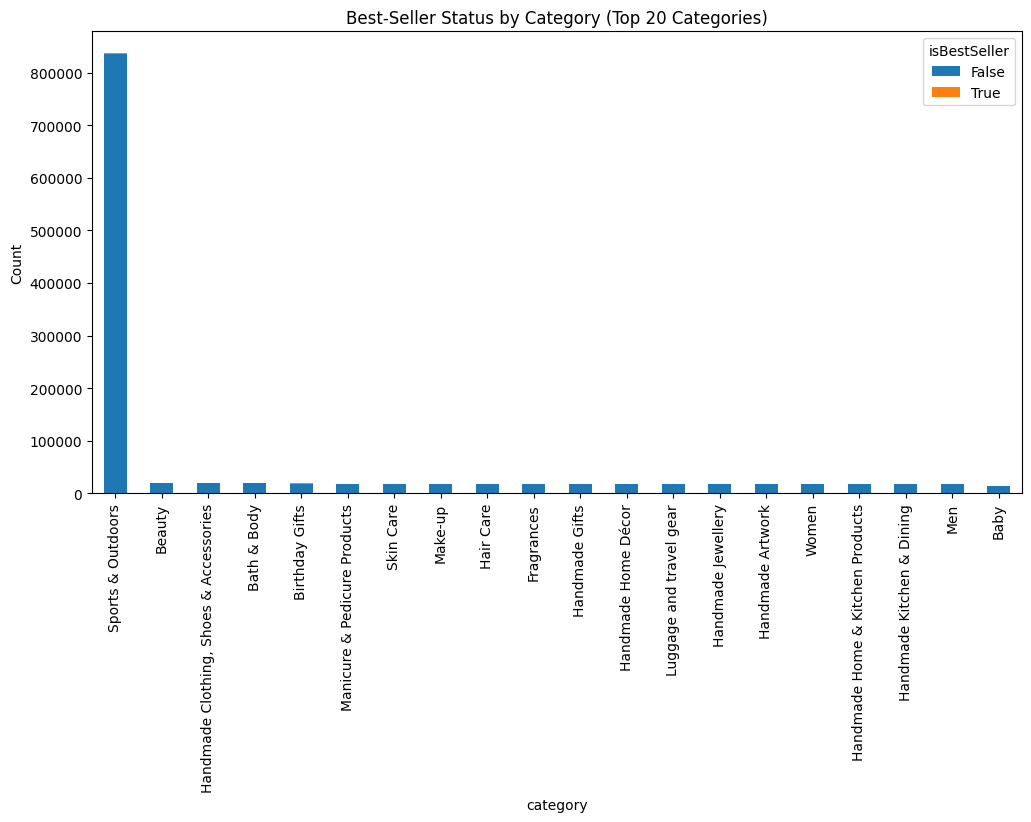

In [5]:
# Visualize top 20 categories for readability
top_cats = df['category'].value_counts().nlargest(20).index
crosstab_filtered = crosstab.loc[top_cats]

crosstab_filtered.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Best-Seller Status by Category (Top 20 Categories)')
plt.ylabel('Count')
plt.show()

In [6]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create a dataframe without outliers
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)].copy()

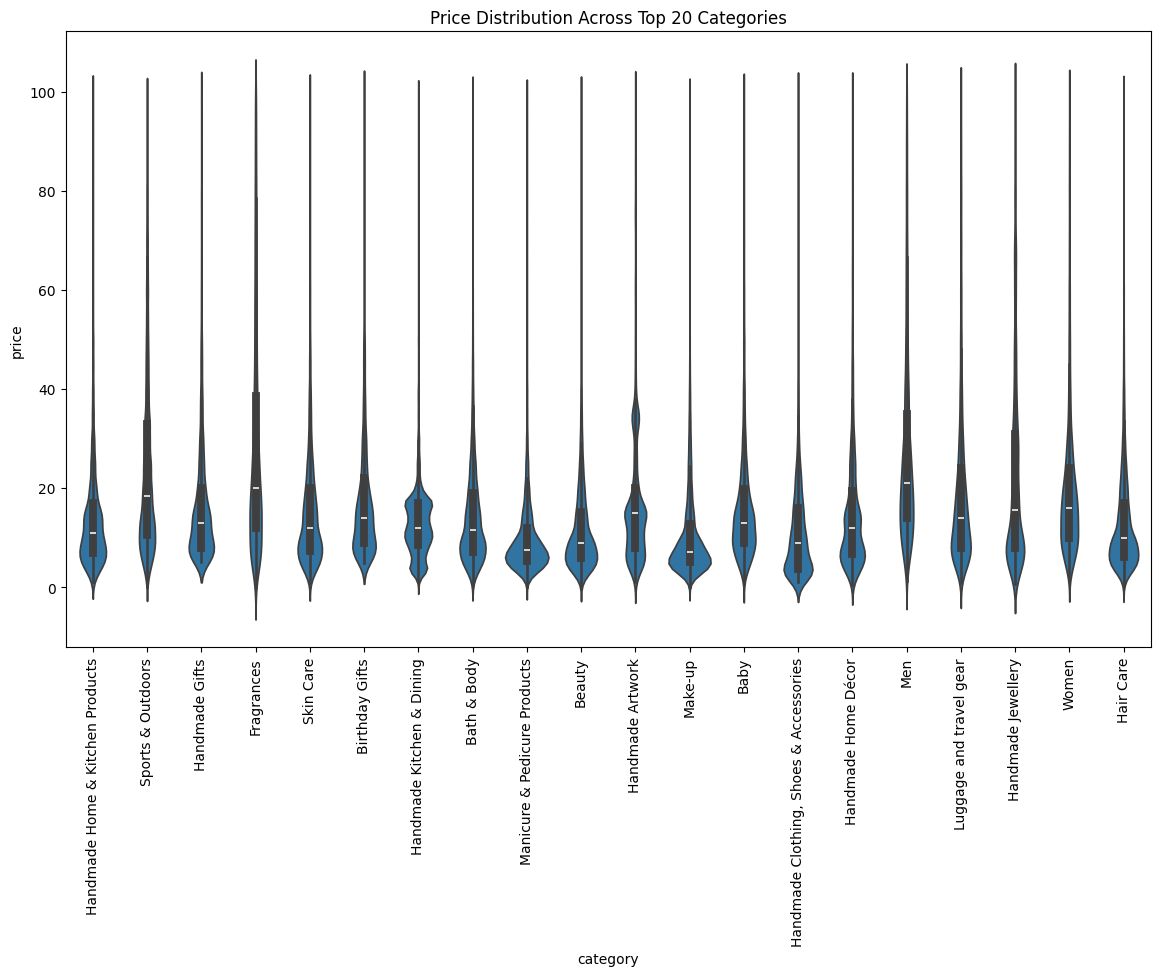

Category with highest median price: Desktop PCs


In [7]:
# Top 20 categories by count
top_20_cats = df_clean['category'].value_counts().nlargest(20).index
df_top_20 = df_clean[df_clean['category'].isin(top_20_cats)]

plt.figure(figsize=(14, 8))
sns.violinplot(x='category', y='price', data=df_top_20)
plt.xticks(rotation=90)
plt.title('Price Distribution Across Top 20 Categories')
plt.show()

# Highest median price (on full cleaned data)
highest_median_price_cat = df_clean.groupby('category')['price'].median().idxmax()
print(f"Category with highest median price: {highest_median_price_cat}")

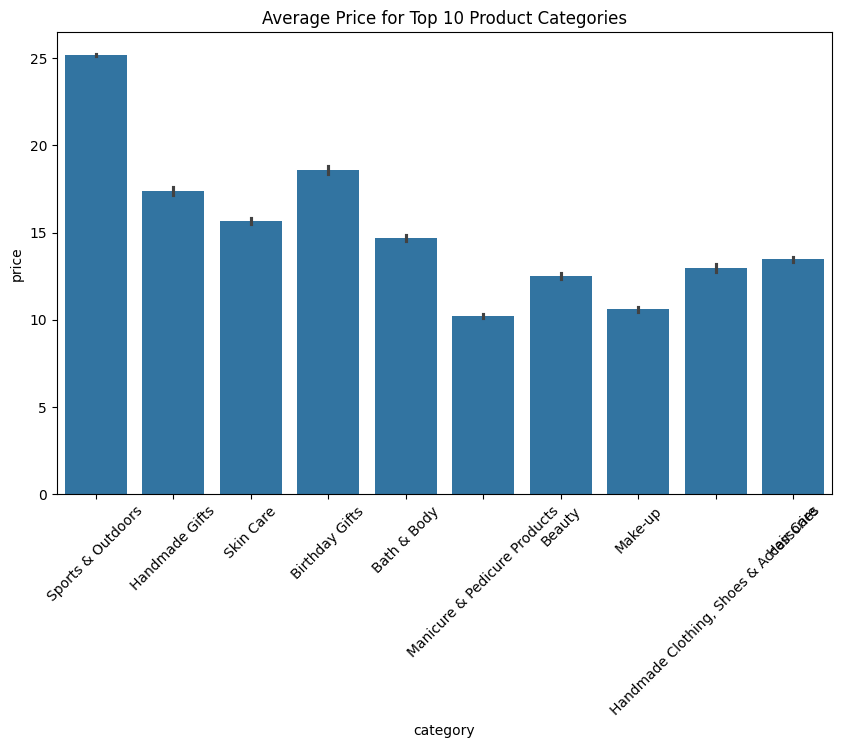

Category with highest average price: Motherboards


In [8]:
# Average price for top 10 categories
top_10_cats = df_clean['category'].value_counts().nlargest(10).index
df_top_10 = df_clean[df_clean['category'].isin(top_10_cats)]

plt.figure(figsize=(10, 6))
sns.barplot(x='category', y='price', data=df_top_10, estimator=np.mean)
plt.xticks(rotation=45)
plt.title('Average Price for Top 10 Product Categories')
plt.show()

# Highest average price (full cleaned data)
highest_avg_price_cat = df_clean.groupby('category')['price'].mean().idxmax()
print(f"Category with highest average price: {highest_avg_price_cat}")

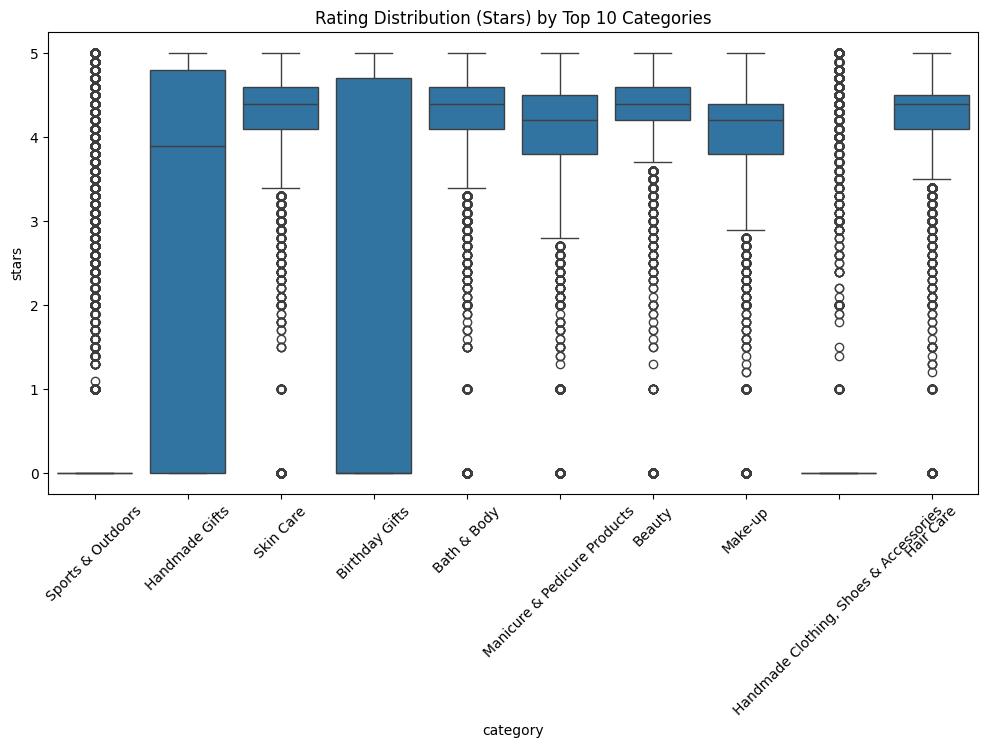

Category with highest median rating: Computer Memory


In [9]:
# Distribution of ratings for top 10 categories
plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=df_top_10)
plt.xticks(rotation=45)
plt.title('Rating Distribution (Stars) by Top 10 Categories')
plt.show()

# Highest median rating (full cleaned data)
highest_median_rating_cat = df_clean.groupby('category')['stars'].median().idxmax()
print(f"Category with highest median rating: {highest_median_rating_cat}")

In [10]:
correlation = df_clean['price'].corr(df_clean['stars'])
print(f"Correlation between Price and Stars: {correlation}")

Correlation between Price and Stars: -0.07767299878178476


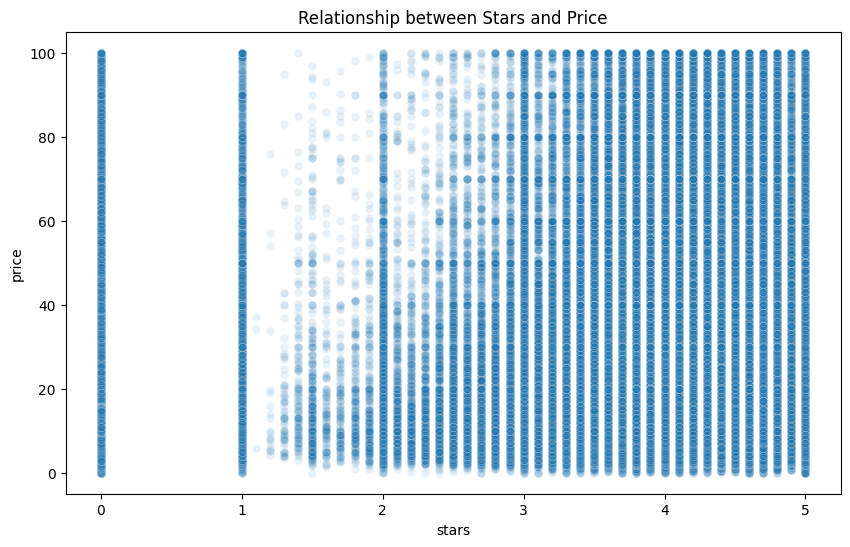

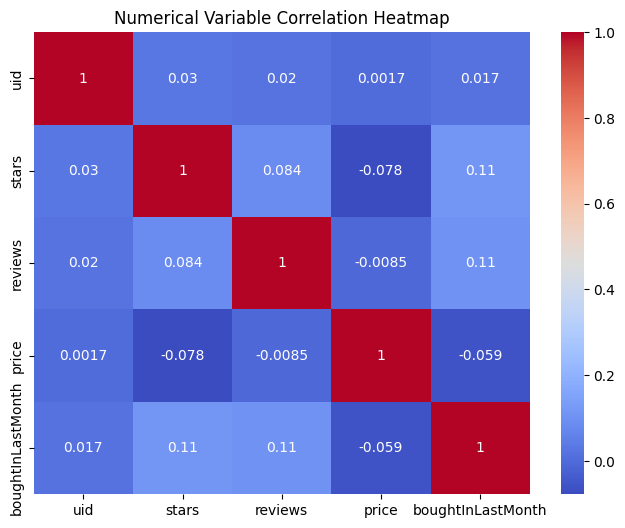

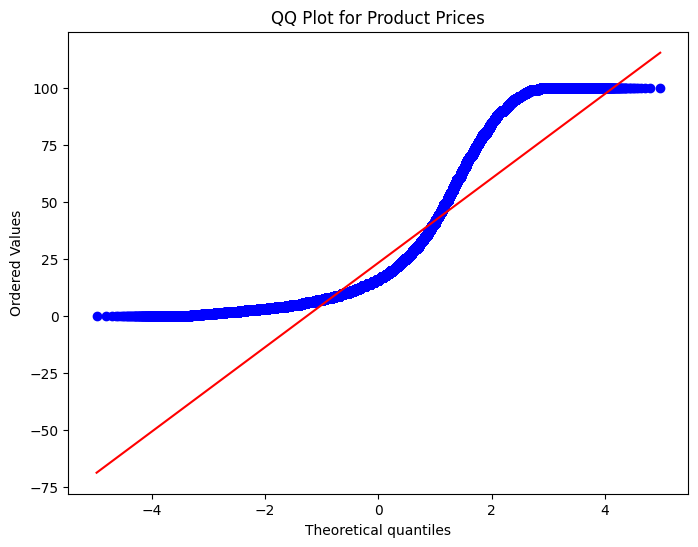

In [11]:
# Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(x='stars', y='price', data=df_clean, alpha=0.1)
plt.title('Relationship between Stars and Price')
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm')
plt.title('Numerical Variable Correlation Heatmap')
plt.show()

# QQ Plot for Normality
plt.figure(figsize=(8, 6))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title('QQ Plot for Product Prices')
plt.show()

In [ ]:
'''
Summary findings
Best-Sellers: The Chi-square test shows that best-seller status is not independent of category, the best one seems to be sports and outdoors.

Price Distributions: The violin plots show that while some categories have high averages, most prices are clustered at the lower end (right-skewed).

Price vs. Stars: Low to no correlation between price and rating. This suggests that a higher price does not necessarily guarantee a higher customer rating on Amazon UK.

Normality: The QQ plot shows that prices are not normally distributed, even after removing outliers, as they usually follow a power-law or highly skewed distribution.
'''